In [1]:
import random as rd

Variant = 21
rd.seed(Variant+86554338)

Numbers_of_problems = [rd.sample(range(5),1)[0]+1, rd.sample(range(5),1)[0]+1, rd.sample(range(5),1)[0]+1]
Numbers_of_problems

[3, 1, 4]

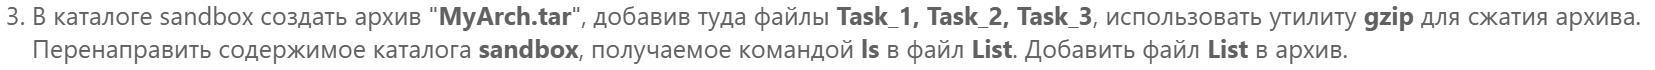

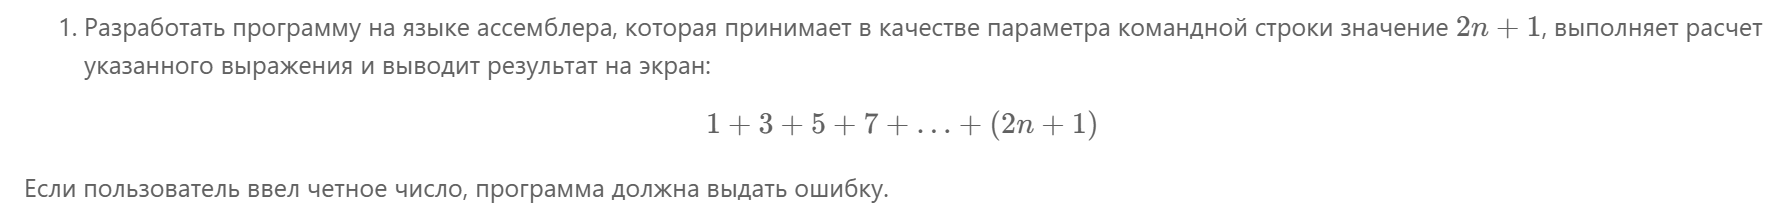

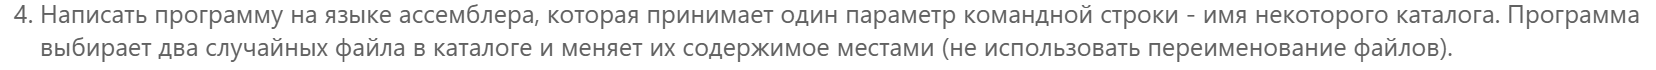

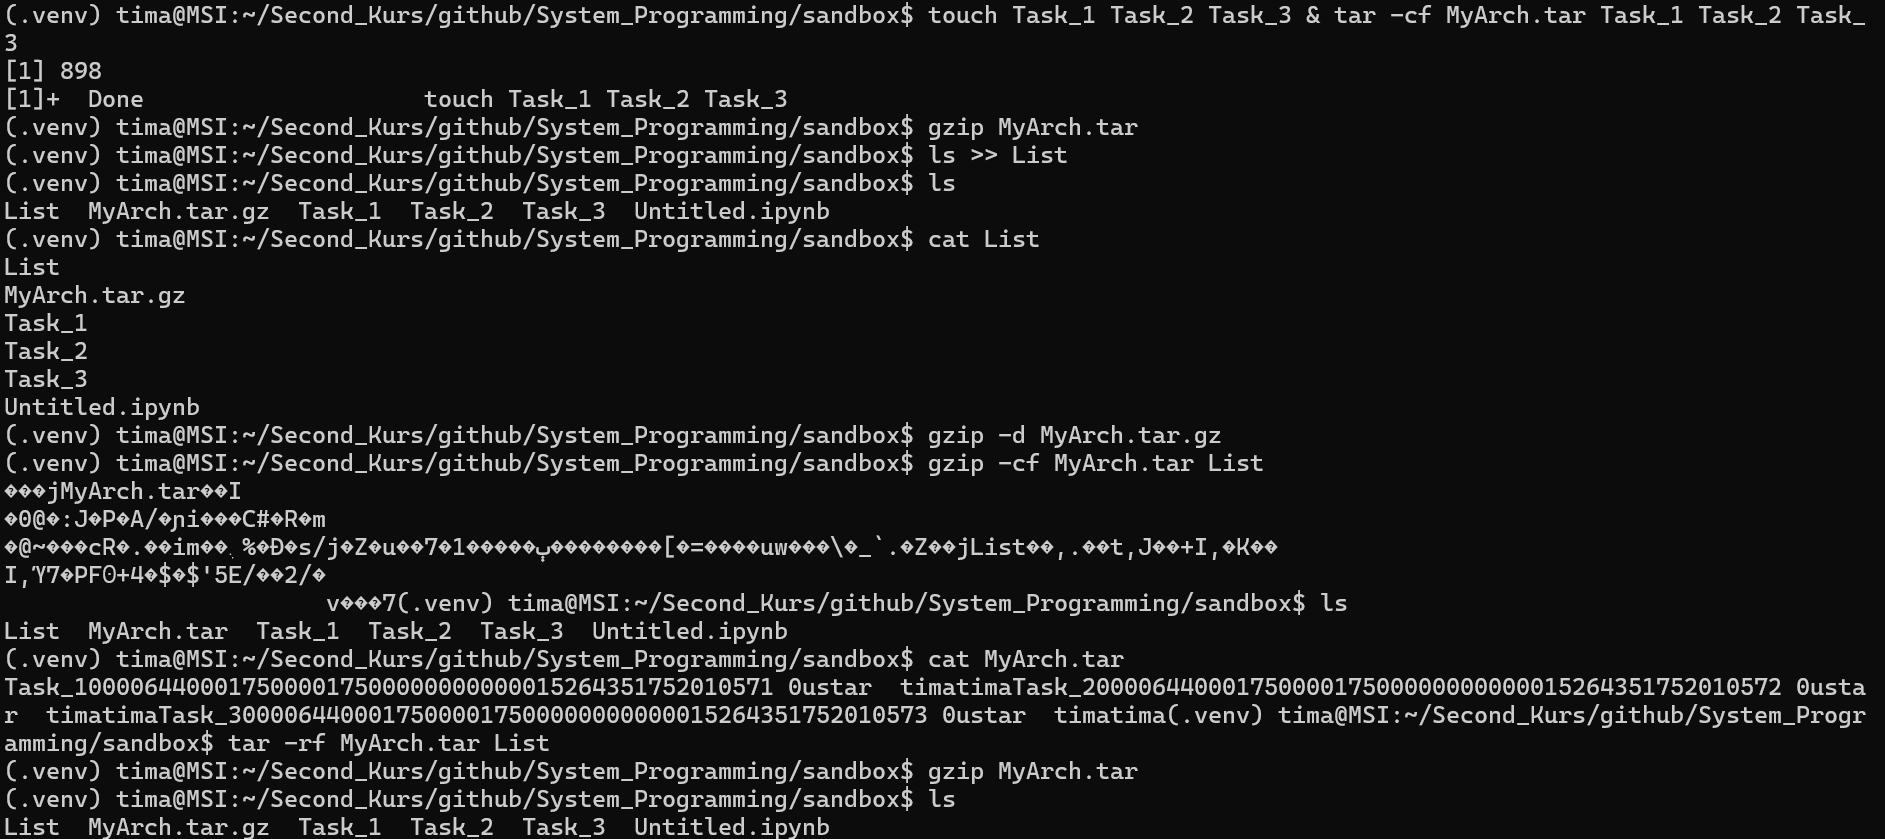

In [ ]:
touch Task_1 Task_2 Task_3 & tar -cf MyArch.tar Task_1 Task_2 Task_
gzip MyArch.tar
ls >> List
gzip -d MyArch.tar.gz
gzip MyArch.tar

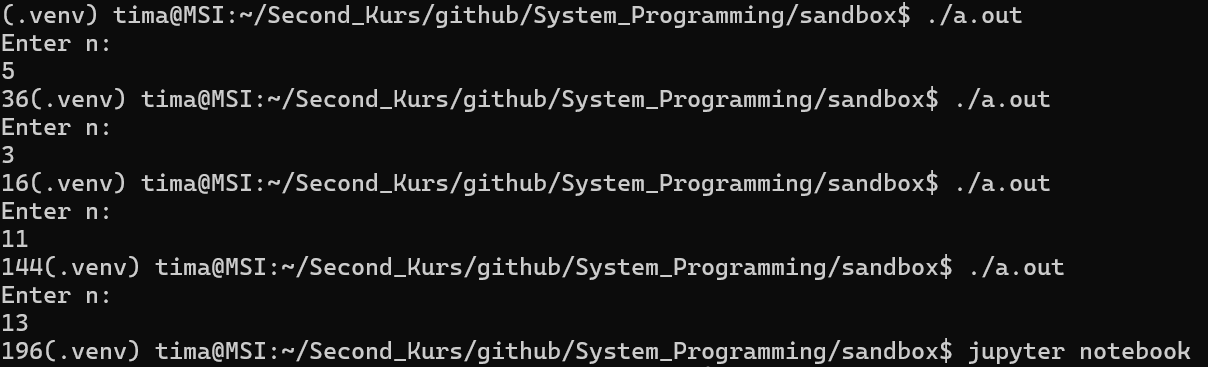

In [ ]:
format ELF64
public _start
public input
public convert_ascii_int
public convert_int_ascii
public print_msg
public ex_1
public _exit

section '.data' writable
	msg_1 db "Enter n:", 0xA, 0
	l_msg_1 = $ - msg_1

	msg_2 db "ERROR 2", 0xA, 0
	l_msg_2 = $ - msg_2

section '.bss' writable
	buffer rd 256 ; Для хранения ввода
	buffer_2 rd 256 ; Для хранения вывода
	accumulat rq 1

section '.text' executable
_start:
	mov rsi, msg_1
	mov rdx, l_msg_1
	call  print_msg

	call input

	call convert_ascii_int

	call ex_1	

	call convert_int_ascii


	mov rsi, buffer_2
	add rsi, rdx
	mov rax, 256
	sub rax, rdx
	mov rdx, rax
	call print_msg 

	call _exit

input: ;Метка для ввода
	xor rax, rax
	mov rdi, 0
	mov rsi, buffer ; Буфер для записи с клавиатуры
	mov rdx, 256

	syscall ; Системный вызов в виде прерывания


	xor rbx, rbx
	xor rdx, rdx
	.iter_n:
			cmp byte [rsi + rbx], 0xA
			je .next_n
			inc rbx
			jmp .iter_n

	.next_n:
			mov [rsi + rbx], rdx

	ret

convert_ascii_int: ; Перевод из ascii нотации в int. В rsi хранится адрес, rdx - длина.
	; rax - аккумулятор числа
	xor rax, rax

	.iter:
			cmp byte [rsi], 0
			je .next
			mov dl, byte [rsi]
			sub dl, '0'
			push rdx
			mov rdx, 10
			mul rdx
			pop rdx
			add rax, rdx
			inc rsi ; Следующая цифра

			jmp .iter

	.next:
			mov [accumulat], rax

			ret

convert_int_ascii:
	mov rax, [accumulat]
	mov rdx, rax
	mov rsi, buffer_2

	mov rbx, 255
	mov rcx, 10

	.iter_2:
			cmp rax, 0
			je .next_2

			xor rdx, rdx
			div rcx
			add dl, '0'
			mov [rsi + rbx], dl
			dec rbx

			jmp .iter_2

	.next_2:
			ret

ex_1:
	mov rax, [accumulat]
	push rax
	xor rdx, rdx
	mov [accumulat], rdx
	mov rcx, 2

	div rcx 

	cmp rdx, 0
	je .error
		
	pop rax ; rax = n
	mul rcx ; rax = 2n
	xor rdx, rdx
	inc rax
	
	.iter:
		cmp rax, 1
		je .next
		add [accumulat], rax
		sub rax, 2
		jmp .iter

	.next:
		add [accumulat], rax
		ret

	.error:
		pop rax
		mov rsi, msg_2
        	mov rdx, l_msg_2
	
		call print_msg	
	
		ret

print_msg: ; Вызов вывода в командную строку
	mov rax, 1
	mov rdi, 1
	
	syscall

	ret

section '.exit' executable
_exit:
	mov rax, 60
	mov rdi, 0
	
	syscall


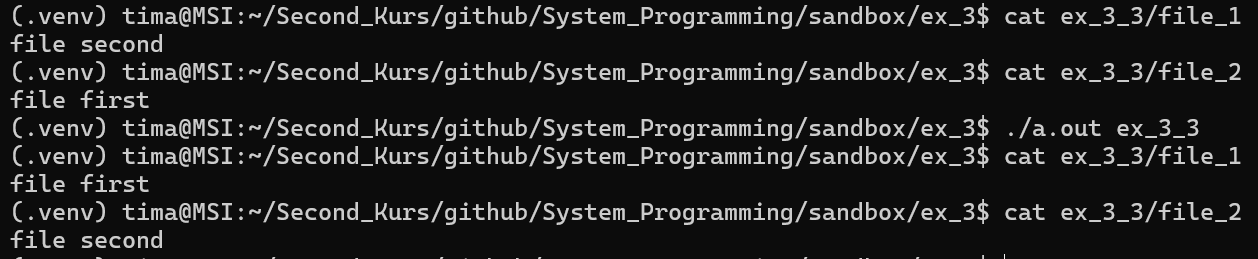

In [ ]:
format elf64
public _start

include 'func.asm'

BUF_SIZE = 1048576          ; максимальный размер файла (1 МБ)

section '.bss' writable

  dir_path   dq ?
  file1_name rb 4400
  file2_name rb 4400
  buf1       rb BUF_SIZE
  buf2       rb BUF_SIZE
  dir_buf    rb 4096
  size1      dq ?
  size2      dq ?
  file_count dq 0
  rand_buf   rq 2
  names_ptr  rq 64
  name_storage rb 64*256

section '.text' executable

_start:
  pop rcx                   ; argc
  cmp rcx, 1
  je .exit

  mov rdi, [rsp+8]          ; argv[1]
  mov [dir_path], rdi

  ; открытие каталога (O_RDONLY | O_DIRECTORY)
  mov rax, 2
  mov rsi, 65536
  xor rdx, rdx
  syscall
  cmp rax, 0
  jl .exit
  mov r8, rax               ; дескриптор каталога

  ; чтение каталога (getdents64) в цикле, пока не вернёт 0
.read_dir:
  mov rax, 217
  mov rdi, r8
  mov rsi, dir_buf
  mov rdx, 4096
  syscall
  cmp rax, 0
  jl .parse_done            ; ошибка
  je .parse_done            ; конец каталога

  mov r9, rax               ; сколько байт прочитано
  mov r12, dir_buf
  xor r13, r13

.parse_loop:
  cmp r13, r9
  jb .parse_body            ; ещё есть записи
  jmp .read_dir             ; буфер разобран, читаем следующую порцию

.parse_body:
  xor rdx, rdx
  mov dx, [r12 + 16]        ; d_reclen
  cmp rdx, 0
  je .parse_done

  ; только обычные файлы (DT_REG == 8)
  cmp byte [r12 + 18], 8
  jne .next_entry

  mov rsi, r12
  add rsi, 19               ; d_name

  ; пропускаем "." и ".."
  cmp byte [rsi], '.'
  jne .save_file
  cmp byte [rsi + 1], 0
  je .next_entry
  cmp byte [rsi + 1], '.'
  jne .save_file
  cmp byte [rsi + 2], 0
  je .next_entry

.save_file:
  mov rax, [file_count]
  cmp rax, 64
  jb .do_save               ; место ещё есть
  jmp .next_entry

.do_save:
  mov rdi, rax
  shl rdi, 8
  add rdi, name_storage     ; куда копируем имя

  mov rdx, rax
  shl rdx, 3
  add rdx, names_ptr
  mov [rdx], rdi            ; names_ptr[i] = адрес имени

  call copy_string
  inc qword [file_count]

.next_entry:
  xor rdx, rdx
  mov dx, [r12 + 16]
  add r12, rdx
  add r13, rdx
  jmp .parse_loop

.parse_done:
  cmp qword [file_count], 2
  jb .close_dir

  ; случайные числа через getrandom
  mov rax, 318
  mov rdi, rand_buf
  mov rsi, 16
  xor rdx, rdx
  syscall
  cmp rax, 0
  jl .close_dir

  ; первый индекс: 0..n-1
  mov rax, [rand_buf]
  xor rdx, rdx
  div qword [file_count]
  mov r9, rdx

  ; второй индекс: 0..n-2, и если >= первого, сдвигаем на 1
  mov rax, [rand_buf + 8]
  xor rdx, rdx
  mov rcx, [file_count]
  dec rcx
  div rcx
  mov r10, rdx
  cmp r10, r9
  jb .have_indices
  inc r10

.have_indices:
  ; полный путь первого файла
  mov rax, r9
  shl rax, 3
  add rax, names_ptr
  mov rsi, [rax]
  mov rdi, file1_name
  call build_path

  ; полный путь второго файла
  mov rax, r10
  shl rax, 3
  add rax, names_ptr
  mov rsi, [rax]
  mov rdi, file2_name
  call build_path

  ; читаем первый файл
  mov rdi, file1_name
  mov rsi, buf1
  mov rdx, BUF_SIZE
  call read_file
  cmp rax, 0
  jl .close_dir
  mov [size1], rax

  ; читаем второй файл
  mov rdi, file2_name
  mov rsi, buf2
  mov rdx, BUF_SIZE
  call read_file
  cmp rax, 0
  jl .close_dir
  mov [size2], rax

  ; в первый пишем содержимое второго
  mov rdi, file1_name
  mov rsi, buf2
  mov rdx, [size2]
  call write_file
  cmp rax, 0
  jl .close_dir

  ; во второй пишем содержимое первого
  mov rdi, file2_name
  mov rsi, buf1
  mov rdx, [size1]
  call write_file

.close_dir:
  mov rax, 3
  mov rdi, r8
  syscall

.exit:
  call exit

; copy_string: rsi = откуда, rdi = куда (до нулевого байта)
copy_string:
  push rax
  push rcx
  xor rcx, rcx
.loop:
  mov al, [rsi + rcx]
  mov [rdi + rcx], al
  inc rcx
  cmp al, 0
  jne .loop
  pop rcx
  pop rax
  ret

; build_path: rdi = куда, rsi = имя файла
build_path:
  push rax
  push rdi
  push rsi
  mov rsi, [dir_path]
.dir:
  mov al, [rsi]
  cmp al, 0
  je .slash
  mov [rdi], al
  inc rsi
  inc rdi
  jmp .dir
.slash:
  mov byte [rdi], '/'
  inc rdi
  mov rsi, [rsp]            ; имя файла (сохранённый rsi)
.name:
  mov al, [rsi]
  mov [rdi], al
  inc rsi
  inc rdi
  cmp al, 0
  jne .name
  pop rsi
  pop rdi
  pop rax
  ret

; read_file: rdi = путь, rsi = буфер, rdx = ёмкость буфера
; возвращает rax = размер прочитанного или отрицательное число при ошибке
; (если файл не поместился в буфер - тоже ошибка)
read_file:
  push rbx
  push r12
  push r13
  push r14
  mov r12, rsi
  mov r13, rdx
  xor r14, r14              ; прочитано всего

  mov rax, 2
  xor rsi, rsi              ; O_RDONLY
  xor rdx, rdx
  syscall
  cmp rax, 0
  jl .done
  mov rbx, rax              ; fd

.loop:
  mov rdx, r13
  sub rdx, r14              ; сколько места осталось
  cmp rdx, 0
  je .full                  ; буфер заполнен, файл может быть больше
  mov rsi, r12
  add rsi, r14              ; куда читать дальше
  mov rax, 0
  mov rdi, rbx
  syscall
  cmp rax, 0
  jl .err
  je .eof
  add r14, rax
  jmp .loop

.full:
  mov r14, -1
  jmp .eof
.err:
  mov r14, rax
.eof:
  mov rax, 3
  mov rdi, rbx
  syscall
  mov rax, r14
.done:
  pop r14
  pop r13
  pop r12
  pop rbx
  ret

; write_file: rdi = путь, rsi = данные, rdx = длина
; перезаписывает файл (O_WRONLY | O_CREAT | O_TRUNC)
; возвращает rax = 0 или отрицательное число при ошибке
write_file:
  push rbx
  push r12
  push r13
  mov r12, rsi
  mov r13, rdx

  mov rax, 2
  mov rsi, 577
  mov rdx, 666o
  syscall
  cmp rax, 0
  jl .done
  mov rbx, rax              ; fd

.loop:
  cmp r13, 0
  je .ok
  mov rax, 1
  mov rdi, rbx
  mov rsi, r12
  mov rdx, r13
  syscall
  cmp rax, 0
  jl .err
  je .err                   ; записано 0 байт - считаем ошибкой
  add r12, rax
  sub r13, rax
  jmp .loop

.err:
  mov rax, 3
  mov rdi, rbx
  syscall
  mov rax, -1
  jmp .done
.ok:
  mov rax, 3
  mov rdi, rbx
  syscall
  xor rax, rax
.done:
  pop r13
  pop r12
  pop rbx
  ret
